In [70]:
#imports
# pip install linearmodels
import pandas as pd
import numpy as np
import statsmodels.api as sm  
from linearmodels.system import SUR

# Data

In [46]:
stock_df = pd.read_csv("/home/jovyan/Fall_2026/data_mining/Natural_Disaster_Stock_Market/data/stock_data/market_raw.csv")
hurricane_df = pd.read_csv("/home/jovyan/Fall_2026/data_mining/Natural_Disaster_Stock_Market/data/disaster_data/emdat_noaa_matched.csv")
hurricane_df['start_date'] = pd.to_datetime(hurricane_df['start_date'], format='%Y-%m-%d')  
hurricane_df['end_date'] = pd.to_datetime(hurricane_df['end_date'], format='%Y-%m-%d')  
print("Hurricane Columns: ", hurricane_df.columns)
print("Stock Columns: ", stock_df.columns)
#there are a lot of variable we can add to a SUR model, going to start with just returns, VIX closing, and hurrican booean

Hurricane Columns:  Index(['storm_id', 'hurricane_name', 'season', 'DisNo.', 'Classification Key',
       'ISO', 'Region', 'AID Contribution ('000 US$)', 'Total Deaths',
       'No. Injured', 'No. Affected', 'Total Affected',
       'Insured Damage ('000 US$)', 'Insured Damage, Adjusted ('000 US$)',
       'Total Damage ('000 US$)', 'Total Damage, Adjusted ('000 US$)', 'CPI',
       'peak_category', 'peak_wind_kts', 'peak_wind_mph', 'min_pressure_mb',
       'start_date', 'end_date', 'duration_days', 'landfall_status',
       'landfall_category', 'landfall_lat', 'landfall_lon',
       'landfall_wind_kts'],
      dtype='object')
Stock Columns:  Index(['Date', 'SPY_Open', 'SPY_High', 'SPY_Low', 'SPY_Close', 'SPY_Volume',
       'XLE_Open', 'XLE_High', 'XLE_Low', 'XLE_Close', 'XLE_Volume',
       'XLF_Open', 'XLF_High', 'XLF_Low', 'XLF_Close', 'XLF_Volume',
       'XLI_Open', 'XLI_High', 'XLI_Low', 'XLI_Close', 'XLI_Volume',
       'XLU_Open', 'XLU_High', 'XLU_Low', 'XLU_Close', 'XLU_Volu

In [ ]:
# for US hurricanes only
df = pd.DataFrame()
#'Date', 'SPY_return', 'XLE_return', 'XLF_return', 'XLI_return', 'XLU_return', 'VIX_close'
df['date'] = pd.to_datetime(stock_df["Date"], format='%Y-%m-%d')
df['SPY_return'] = ((stock_df['SPY_Close'] -stock_df['SPY_Open'])/stock_df['SPY_Open'])*100 
df['XLE_return'] = ((stock_df['XLE_Close'] -stock_df['XLE_Open'])/stock_df['XLE_Open'])*100 
df['XLF_return'] = ((stock_df['XLF_Close'] -stock_df['XLF_Open'])/stock_df['XLF_Open'])*100 
df['XLI_return'] = ((stock_df['XLI_Close'] -stock_df['XLI_Open'])/stock_df['XLI_Open'])*100 
df['XLU_return'] = ((stock_df['XLU_Close'] -stock_df['XLU_Open'])/stock_df['XLU_Open'])*100 
df['VIX_close'] =stock_df['^VIX_Close']
us_hurricane_df = hurricane_df[hurricane_df["ISO"]=="USA"]
df['during_hurricane'] = df['date'].apply(
    lambda date: (
        (us_hurricane_df['start_date'] <= date) &
        (us_hurricane_df['end_date'] >= date)
    ).any()
)
df["during_hurricane"] = (df["during_hurricane"].astype(int))
df.head()

,date,SPY_return,XLE_return,XLF_return,XLI_return,XLU_return,VIX_close,during_hurricane
0,1999-11-24,0.865897,1.374570,-0.062975,0.500556,-0.381063,20.26,0
1,1999-11-26,-0.723843,-0.683371,-1.376716,0.111359,0.597833,22.33,0
2,1999-11-29,0.044366,-0.288191,-1.029601,0.056593,-0.218103,23.57,0
3,1999-11-30,-1.043517,-0.115674,1.690511,-0.339751,0.379205,24.18,0
4,1999-12-01,0.785105,2.146179,0.258388,0.566893,0.648649,22.23,0


In [ ]:
#for all hurricanes worldwide
df = pd.DataFrame()
#'Date', 'SPY_return', 'XLE_return', 'XLF_return', 'XLI_return', 'XLU_return', 'VIX_close'
df['date'] = pd.to_datetime(stock_df["Date"], format='%Y-%m-%d')
df['SPY_return'] = ((stock_df['SPY_Close'] -stock_df['SPY_Open'])/stock_df['SPY_Open'])*100 
df['XLE_return'] = ((stock_df['XLE_Close'] -stock_df['XLE_Open'])/stock_df['XLE_Open'])*100 
df['XLF_return'] = ((stock_df['XLF_Close'] -stock_df['XLF_Open'])/stock_df['XLF_Open'])*100 
df['XLI_return'] = ((stock_df['XLI_Close'] -stock_df['XLI_Open'])/stock_df['XLI_Open'])*100 
df['XLU_return'] = ((stock_df['XLU_Close'] -stock_df['XLU_Open'])/stock_df['XLU_Open'])*100 
df['VIX_close'] =stock_df['^VIX_Close']
df['during_hurricane'] = df['date'].apply(
    lambda date: (
        (hurricane_df['start_date'] <= date) &
        (hurricane_df['end_date'] >= date)
    ).any()
)
df["during_hurricane"] = (df["during_hurricane"].astype(int))
df.head()

In [48]:
#validate data is complete
print(df.isna().sum())
print(df.info())
print(df["during_hurricane"].value_counts())

date                0
SPY_return          0
XLE_return          0
XLF_return          0
XLI_return          0
XLU_return          0
VIX_close           0
during_hurricane    0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6538 entries, 0 to 6537
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              6538 non-null   datetime64[ns]
 1   SPY_return        6538 non-null   float64       
 2   XLE_return        6538 non-null   float64       
 3   XLF_return        6538 non-null   float64       
 4   XLI_return        6538 non-null   float64       
 5   XLU_return        6538 non-null   float64       
 6   VIX_close         6538 non-null   float64       
 7   during_hurricane  6538 non-null   int64         
dtypes: datetime64[ns](1), float64(6), int64(1)
memory usage: 408.8 KB
None
during_hurricane
0    6152
1     386
Name: count, dtype: int64


# OLS regression

In [ ]:
model_df = df.dropna(
    subset=[
        "XLF_return",
        "SPY_return",
        "VIX_close",
        "during_hurricane"
    ]
).copy()

X = model_df[
    ["SPY_return", "VIX_close", "during_hurricane"]
]

y = model_df["XLF_return"]

X = sm.add_constant(np.asarray(X))

# model = sm.OLS(y, X).fit()
model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             XLF_return   R-squared:                       0.625
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                     381.9
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.53e-228
Time:                        21:42:26   Log-Likelihood:                -8608.9
No. Observations:                6538   AIC:                         1.723e+04
Df Residuals:                    6534   BIC:                         1.725e+04
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0306      0.053      0.573      0.5

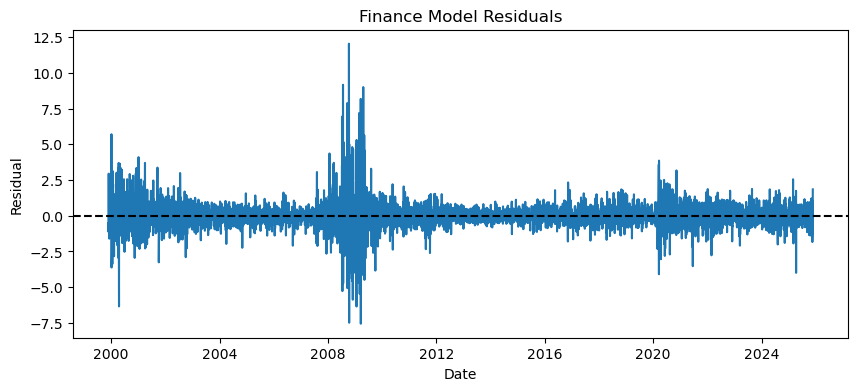

Hurricane coefficient: 0.02617073562302651
Hurricane p-value: 0.5329243520834974
95% CI: [-0.05609026839629286, 0.10843173964234587]
Baseline R²: 0.6253311473633093
Hurricane model R²: 0.625348632423594
Difference: 1.748506028464991e-05


In [65]:
import matplotlib.pyplot as plt

residuals = model.resid

plt.figure(figsize=(10, 4))
plt.plot(model_df["date"], residuals)
plt.axhline(0, color="black", linestyle="--")
plt.title("Finance Model Residuals")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

print("Hurricane coefficient:", model.params["x3"])
print("Hurricane p-value:", model.pvalues["x3"])
print(
    "95% CI:",
    model.conf_int().loc["x3"].tolist()
)

# Model without hurricane indicator
X_baseline = sm.add_constant(
    model_df[["SPY_return", "VIX_close"]].astype(float)
)

baseline = sm.OLS(y, X_baseline).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

print("Baseline R²:", baseline.rsquared)
print("Hurricane model R²:", model.rsquared)
print("Difference:", model.rsquared - baseline.rsquared)

# SUR Model

In [71]:

regressors = [
    "SPY_return",
    "VIX_close",
    "during_hurricane"
]

data = df.dropna().copy()
data["during_hurricane"] = data["during_hurricane"].astype(int)

X = sm.add_constant(data[regressors].astype(float))

equations = {}

for sector in ["XLE", "XLF", "XLI", "XLU"]:
    equations[sector] = {
        "dependent": data[f"{sector}_return"].astype(float),
        "exog": X
    }

sur_model = SUR(equations)
sur_results = sur_model.fit(cov_type="kernel")

print(sur_results.summary)

                           System OLS Estimation Summary                           
Estimator:                        OLS   Overall R-squared:                   0.5011
No. Equations.:                     4   McElroy's R-squared:                 0.4952
No. Observations:                6538   Judge's (OLS) R-squared:             0.5011
Date:                Sun, Oct 18 2026   Berndt's R-squared:                  0.7973
Time:                        21:55:36   Dhrymes's R-squared:                 0.5011
                                        Cov. Estimator:                      kernel
                                        Num. Constraints:                      None
                   Equation: XLE, Dependent Variable: XLE_return                    
                  Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------
const                0.0434     0.0508     0.8544     0.3929     -0.0561 